# 26 · 倒排索引与BM25

本章把BM25拆成词频、逆文档频率、长度归一化与倒排访问。算法定义与真实训练查询实验同时保留，避免只会调用一个库。

**先预测**：文档里的查询词重复100次，得分会比重复1次高100倍吗？关闭长度归一化后，长摘要是否更占优势？

所有参数敏感性实验只看前30个训练查询，完整语料不缩小；不根据测试分数重新选择正式配置。

**学习导航：** [上一章](25_Search_Task_Qrels.ipynb) · [下一章](27_Search_Semantic.ipynb) · [综合实验](17_Search_Experiments.ipynb)

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if not (root / 'reclab').exists(): root = root.parent
os.chdir(root); sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from reclab.search_lessons import context, query_vectors, score_query, labels
from reclab.search import BM25, rrf
from reclab.retrieval import topk, metrics
ctx = context()
print('Shared search run:', ctx['receipt']['run_id'])

Shared search run: 20261030T124927-d1467622


## 1. 稀疏矩阵就是可检查的倒排索引

`X[d,t]`记录文档d中词t的计数，形状是文档数×词表大小。稀疏矩阵只存非零项；按词列访问，即得到包含该词的文档。当前实现使用小写单词切分，无停用词过滤或词干化。该选择本身也是假设。

In [2]:
model=ctx['bm25']; index=model.index
print('document-term matrix:',index.shape,'nonzeros:',index.nnz)
term='vitamin'; col=model.vectorizer.vocabulary_.get(term)
if col is not None:
    posting=index[:,col].tocoo()
    print('term:',term,'documents containing term:',len(posting.data))
    display(pd.DataFrame({'internal_doc_idx':posting.row[:8]+1,'weighted_tf':posting.data[:8]}))
print('sparse bytes:',index.data.nbytes+index.indices.nbytes+index.indptr.nbytes)

document-term matrix: (5183, 35954) nonzeros: 633946
term: vitamin documents containing term: 57


,internal_doc_idx,weighted_tf
0,256,4.455640
1,266,5.693689
2,307,8.608077
3,318,8.635369
4,328,4.074860
5,428,3.835336
6,433,8.454129
7,517,8.099405


sparse bytes: 7628088


## 2. 词频饱和不是线性计数

每个查询词贡献为`IDF * tf*(k1+1)/(tf+k1*(1-b+b*dl/avgdl))`，`IDF=log(1+(N-df+.5)/(df+.5))`。k1控制词频饱和，b控制长度惩罚；常见词IDF较小。

**改一个变量**：保持长度相同，只增加tf，画出饱和曲线。该图是公式机制，不是实际语料效果。

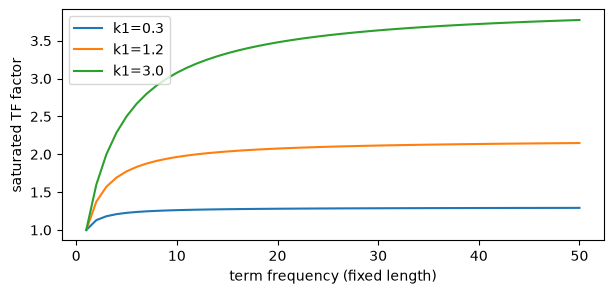

In [3]:
tf=np.arange(1,51)
fig,ax=plt.subplots(figsize=(7,3))
for k1 in [.3,1.2,3.]: ax.plot(tf,tf*(k1+1)/(tf+k1),label=f'k1={k1}')
ax.set(xlabel='term frequency (fixed length)',ylabel='saturated TF factor');ax.legend();plt.show()
small=BM25(['cat cat dog','dog'])
expected=np.log(2)*(2*2.2)/(2+1.2*(.25+.75*3/2))
assert np.isclose(small.score('cat')[1],expected)

## 3. 真正改动长度归一化

现在只变b，固定k1、文档、查询和qrels。每行都是同一30个训练查询的宏平均，不混用测试集。BM25可以在没有训练标签时建索引；这不意味着参数无需验证。

In [4]:
qids=sorted(ctx['truth']['train'])[:30]
rows=[]
for b in [0.,.75,1.]:
    lexical=BM25(ctx['texts'],b=b)
    pred={q:topk(lexical.score(ctx['queries'][q]),10) for q in qids}
    rows.append({'b':b,**metrics(pred,labels(qids,'train'),10)})
display(pd.DataFrame(rows))
print('30 train queries, full corpus; no test-based selection.')

,b,recall@10,ndcg@10,mrr@10,hit_rate@10
0,0.00,0.833333,0.735917,0.714815,0.833333
1,0.75,0.833333,0.777934,0.770833,0.833333
2,1.00,0.833333,0.765631,0.754167,0.833333


30 train queries, full corpus; no test-based selection.


## 4. 查不到词、重复查询词与并列分数

当前查询词频二值化，重复一个词不会再增加它的权重；未登录词没有倒排项。完全未登录查询时，所有文档是0分，现有topk按内部ID稳定返回，不能把这种返回误当成有效匹配。生产产品可以另加零分过滤，课堂先把边界暴露出来。

In [5]:
assert np.array_equal(model.score('vitamin'),model.score('vitamin vitamin'))
unknown=model.score('zzzznonexistenttoken987654')
assert np.all(unknown[1:]==0)
print('OOV query top IDs (stable zero-score ties):',topk(unknown,5))
print('Interpretation: no lexical evidence, not five relevant matches.')

OOV query top IDs (stable zero-score ties): [1, 2, 3, 4, 5]
Interpretation: no lexical evidence, not five relevant matches.


## 5. 看真实误差再提出下一步假设

从原300查询结果中查看BM25未命中的数量；不要仅展示漂亮案例。词汇不匹配、同义表述和专业缩写可能导致失败，但仅凭分数不能断言原因。下一章用同一语料和qrels检验语义编码是否改善。

In [6]:
per=pd.DataFrame([{'qid':r['qid'],**r['metrics']['bm25']} for r in ctx['per_query']])
print('All test queries:',len(per),'zero-hit queries:',int((per['recall@10']==0).sum()))
display(per[per['recall@10']==0].head(8))

All test queries: 300 zero-hit queries: 57


,qid,recall@10,ndcg@10,mrr@10,hit_rate@10
0,1,0.0,0.0,0.0,0.0
10,1049,0.0,0.0,0.0,0.0
13,1088,0.0,0.0,0.0,0.0
19,1110,0.0,0.0,0.0,0.0
31,1175,0.0,0.0,0.0,0.0
37,1191,0.0,0.0,0.0,0.0
39,1196,0.0,0.0,0.0,0.0
40,1197,0.0,0.0,0.0,0.0


**练习**：仅改变k1，在相同30个训练查询重跑；记录哪些查询改善、哪些退化，再解释为什么平均变化不等于每个查询都变化。查看`reclab.search.BM25`源码，指出建索引与在线查询分别做了什么。